# Dataset 1 — Online Retail II EDA + RFM Classification

## Review 1 — Classification Part A

**Purpose:** Build a complete, explainable customer-level classification pipeline from transaction data.

**Rubric coverage in this notebook:**
- **A1 — Dataset loading & audit (1 mark):** shape, data types, missing values, duplicates and basic target/data checks.
- **A2 — EDA visualisations (2 marks):** feature distributions, correlation heatmap, target distribution and feature-target relationships.
- **A3 — Insight commentary (1 mark):** written observations accompany the major EDA sections.
- **B1 — Data cleaning (1 mark):** missing values, duplicates, transaction validity and outliers are checked with a justified treatment.
- **B2 — Encoding, scaling & splitting (1 mark):** leakage-safe preprocessing and stratified 80/20 split.
- **B3 — Feature engineering (1 mark):** RFM features and a justified classification target.
- **D1 — Classification implementation (2 marks):** all five Part-A algorithms are trained.
- **D2 — Classification evaluation (1 mark):** Accuracy, Precision, Recall, weighted F1, ROC-AUC and confusion matrices.

In [1]:
from pathlib import Path
import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone, BaseEstimator, TransformerMixin
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

sns.set_theme(style="whitegrid")

class IQRClipper(BaseEstimator, TransformerMixin):
    """Cap numeric predictors using IQR bounds learned from fit data only."""
    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        q1 = X_df.quantile(0.25)
        q3 = X_df.quantile(0.75)
        iqr = q3 - q1
        self.lower_ = q1 - 1.5 * iqr
        self.upper_ = q3 + 1.5 * iqr
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        return X_df.clip(self.lower_, self.upper_, axis=1).to_numpy()

RANDOM_STATE = 42
N_JOBS = 2
OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = Path("../data/online_retail_II.xlsx")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. Put online_retail_II.xlsx in data/ and rerun."
    )

print("Loading Online Retail II dataset...")
df = pd.read_excel(DATA_PATH)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
print("Loaded:", DATA_PATH.resolve())
print("Shape:", df.shape)

Loading Online Retail II dataset...


Loaded: D:\ml_eval\new\Retail_ML_Capstone\data\online_retail_II.xlsx
Shape: (525461, 8)


## A1 — Dataset audit

We first report the dataset shape, data types, missing values, duplicate rows, and basic descriptive statistics. This makes data-quality issues visible before any modelling decision.

### A1 — Dataset loading and audit

**What this section demonstrates:** the first rubric item requires the dataset structure and quality to be reported before modelling. We therefore inspect shape, column data types, missing-value counts, duplicate rows and numerical summaries.

**Why it matters:** an ML model is only meaningful after we understand what each column represents and whether the raw data contains quality problems.

In [2]:
print("\n--- Dataset Shape ---")
print(df.shape)

print("\n--- Data Types ---")
print(df.dtypes)

print("\n--- Missing Values ---")
missing_summary = df.isna().sum().sort_values(ascending=False)
print(missing_summary)

print("\n--- Exact Duplicate Rows ---")
print(df.duplicated().sum())

print("\n--- Numeric Summary ---")
display(df[['Quantity', 'Price']].describe().T)

print("\n--- Unique Counts ---")
for col in df.columns:
    print(f"{col:15s}: {df[col].nunique(dropna=True):,}")


--- Dataset Shape ---
(525461, 8)

--- Data Types ---
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

--- Missing Values ---
Customer ID    107927
Description      2928
StockCode           0
Invoice             0
Quantity            0
InvoiceDate         0
Price               0
Country             0
dtype: int64

--- Exact Duplicate Rows ---


6865

--- Numeric Summary ---


,count,mean,std,min,25%,50%,75%,max
Quantity,525461.0,10.337667,107.424110,-9600.00,1.00,3.0,10.00,19152.00
Price,525461.0,4.688834,146.126914,-53594.36,1.25,2.1,4.21,25111.09



--- Unique Counts ---
Invoice        : 28,816
StockCode      : 4,632
Description    : 4,681
Quantity       : 825
InvoiceDate    : 25,296
Price          : 1,606
Customer ID    : 4,383
Country        : 40


### Audit observations

- `Customer ID` contains missing values, so customer-level behavioural features cannot be computed reliably for those rows.
- `Description` has some missing values but is not required for the final RFM model, so we still fill it to keep the cleaned transaction table internally consistent.
- Exact duplicate rows are explicitly checked and removed before customer-level aggregation.
- Transactional extremes are audited rather than blindly deleted because unusually large purchases can be genuine business observations.

### B1 — Data cleaning

**Cleaning strategy:**
1. Remove exact duplicate transaction rows because they repeat the same observation.
2. Remove rows without `Customer ID` because customer-level RFM cannot be computed for anonymous transactions.
3. Fill missing product descriptions with `UNKNOWN` so the cleaned transaction table has no null description values.
4. Audit negative quantities and non-positive prices before building purchase-based RFM features.

The treatment is deliberately justified rather than deleting observations without explanation.

In [3]:
# Exact duplicate treatment
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
print(f"Dropped {duplicate_count:,} exact duplicate rows.")

# Missing-value treatment
original_after_duplicates = df.shape[0]
df_clean = df.dropna(subset=['Customer ID', 'InvoiceDate']).copy()
df_clean['Description'] = df_clean['Description'].fillna('UNKNOWN')

print("\n--- After Missing-Value Cleaning ---")
print("Rows:", len(df_clean))
print(df_clean.isna().sum())

# Transaction validity audit
print("\n--- Transaction Sign Audit ---")
print("Negative Quantity rows:", int((df_clean['Quantity'] < 0).sum()))
print("Non-positive Price rows:", int((df_clean['Price'] <= 0).sum()))

Dropped 6,865 exact duplicate rows.

--- After Missing-Value Cleaning ---
Rows: 410763
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64

--- Transaction Sign Audit ---
Negative Quantity rows: 9816
Non-positive Price rows: 31


## B1 — Outlier audit and treatment

We first audit transaction-level outliers with the IQR rule. Because the final model works at customer level, we then audit the actual modelling predictors (`Recency` and `Monetary`) and apply IQR capping to the data used by the classifiers. The cap limits are learned from training data only, so the held-out test set is never used to define the treatment.


### B1 — Why we cap rather than delete

Removing every statistical outlier could discard genuine high-value customers. We therefore use **IQR capping (winsorisation)** for the final numeric predictors. Values outside the training-set IQR limits are capped at the corresponding lower/upper bound. This is an explicit treatment applied to the actual model inputs.


In [4]:
def iqr_outlier_audit(df_in, columns):
    rows = []
    for col in columns:
        q1 = df_in[col].quantile(0.25)
        q3 = df_in[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        mask = (df_in[col] < lower) | (df_in[col] > upper)
        rows.append({
            'Feature': col,
            'Q1': q1,
            'Q3': q3,
            'IQR Lower Bound': lower,
            'IQR Upper Bound': upper,
            'Outlier Rows': int(mask.sum())
        })
    return pd.DataFrame(rows)

transaction_outlier_audit = iqr_outlier_audit(df_clean, ['Quantity', 'Price'])
print('--- Transaction-level outlier audit ---')
display(transaction_outlier_audit)
transaction_outlier_audit.to_csv(OUTPUT_DIR / 'retail_outlier_audit.csv', index=False)


--- Transaction-level outlier audit ---


,Feature,Q1,Q3,IQR Lower Bound,IQR Upper Bound,Outlier Rows
0,Quantity,2.00,12.00,-13.0,27.0,27342
1,Price,1.25,3.75,-2.5,7.5,34703


## A2 — Raw-data EDA

The rubric asks for feature distributions, target distribution, a correlation heatmap, and feature-target relationships. The raw transaction table contains high-cardinality identifier/text fields, so meaningful distribution plots are used for numeric features and top-category frequency plots are used for categorical/text fields.

### A2 — Exploratory Data Analysis visualisations

The rubric asks for distributions, a correlation heatmap, a target distribution and feature-target relationships. Because the raw transaction table contains identifier/text columns with very high cardinality, distributions are shown for meaningful numeric variables and a country frequency plot is used for a major categorical field.

The correlation heatmap is descriptive only; the final classification features are constructed at customer level.

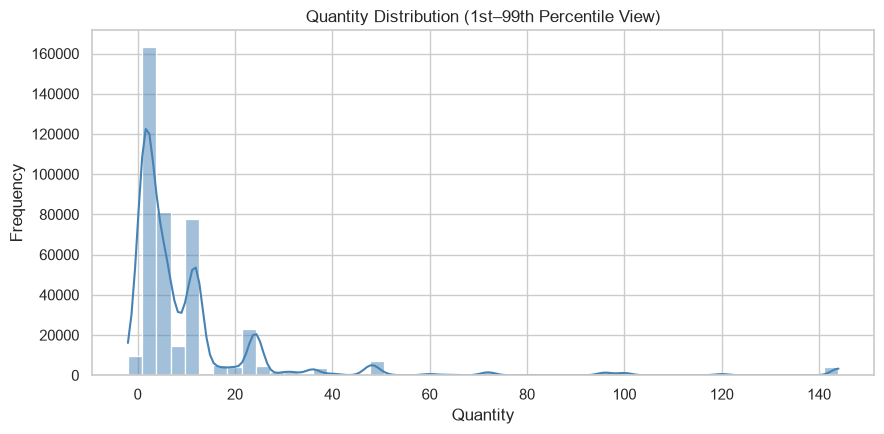

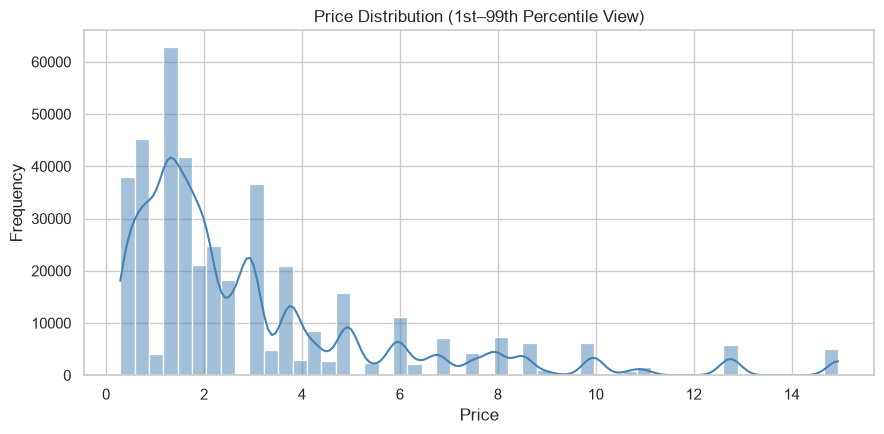

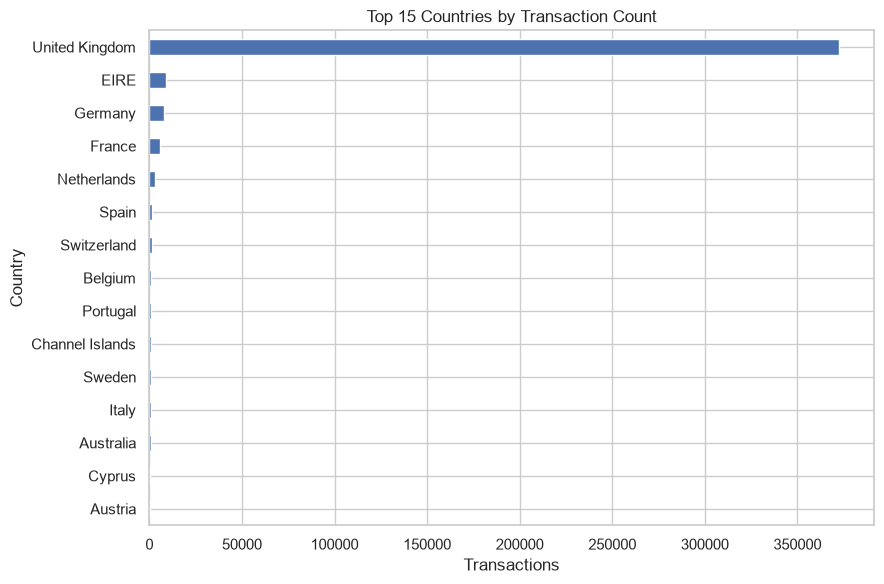

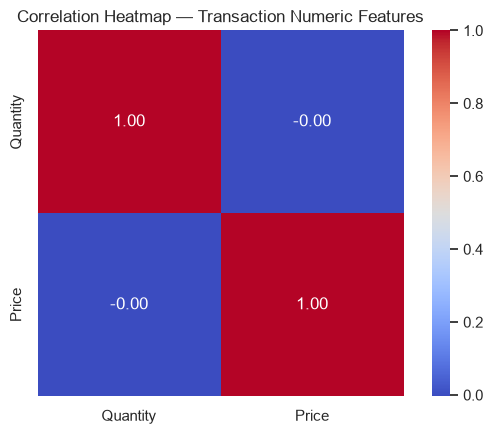

In [5]:
# Numeric feature distributions
for col in ['Quantity', 'Price']:
    plt.figure(figsize=(9, 4.5))
    sns.histplot(df_clean[col].clip(lower=df_clean[col].quantile(0.01), upper=df_clean[col].quantile(0.99)), bins=50, kde=True, color='steelblue')
    plt.title(f'{col} Distribution (1st–99th Percentile View)')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'retail_{col.lower()}_distribution.png', dpi=180, bbox_inches='tight')
    plt.show()

# Country distribution
country_counts = df_clean['Country'].value_counts().head(15).sort_values()
plt.figure(figsize=(9, 6))
country_counts.plot(kind='barh')
plt.title('Top 15 Countries by Transaction Count')
plt.xlabel('Transactions')
plt.ylabel('Country')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'retail_country_distribution.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close('all')

# Correlation heatmap of substantive numeric transaction features
numeric_df = df_clean[['Quantity', 'Price']].copy()
plt.figure(figsize=(6, 4.5))
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Correlation Heatmap — Transaction Numeric Features')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'retail_correlation_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()

### Raw EDA observations

- Quantity and Price are strongly skewed, which is typical of transaction-level retail data.
- The raw `Quantity`/`Price` correlation is useful as a descriptive check, but these are not yet customer-level behavioural features.
- Country is highly imbalanced, with a small number of countries accounting for most transactions.
- High-cardinality fields such as Invoice, StockCode, and Description are not used directly for the customer-behaviour model.

### B3 — Feature engineering: RFM

We transform transaction-level records into one row per customer.

- **Recency:** number of days since the customer's last positive purchase.
- **Frequency:** number of distinct invoices.
- **Monetary:** total value of positive purchases.

A binary target, `Repeat_Customer`, is created from `Frequency > 1`.

**Leakage control:** because Frequency defines the target, it must not be used as an input feature.

In [6]:
# Build RFM features from actual purchase transactions.
# Returns/negative quantities are excluded from RFM because the model is intended to describe purchasing behaviour.
purchases = df_clean[(df_clean['Quantity'] > 0) & (df_clean['Price'] > 0)].copy()
purchases['Total_Price'] = purchases['Quantity'] * purchases['Price']

latest_date = purchases['InvoiceDate'].max() + dt.timedelta(days=1)

rfm = purchases.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (latest_date - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('Total_Price', 'sum')
)

rfm_clean = rfm[rfm['Monetary'] > 0].copy()
rfm_clean['Repeat_Customer'] = (rfm_clean['Frequency'] > 1).astype(int)

print("\n--- RFM Dataset Shape ---")
print(rfm_clean.shape)
display(rfm_clean.head())

print("\n--- Class Distribution ---")
print(rfm_clean['Repeat_Customer'].value_counts().sort_index())


--- RFM Dataset Shape ---
(4312, 4)


,Recency,Frequency,Monetary,Repeat_Customer
Customer ID,,,,
12346.0,165,11,372.86,1
12347.0,3,2,1323.32,1
12348.0,74,1,222.16,0
12349.0,43,3,2671.14,1
12351.0,11,1,300.93,0



--- Class Distribution ---
Repeat_Customer
0    1419
1    2893
Name: count, dtype: int64


## B3 — Customer-level feature engineering
We convert transactions into one row per customer using **RFM**:

- **Recency:** days since the customer's most recent purchase.
- **Frequency:** number of unique purchase invoices.
- **Monetary:** total positive purchase value.
- **Repeat_Customer:** target = 1 when Frequency > 1.

`Frequency` is excluded from the predictors because it directly defines the target. The final model therefore uses **Recency and Monetary** only, avoiding target leakage.

### A2 — Customer-level EDA and target analysis

After RFM aggregation, the modelling population is customer-level rather than transaction-level. We now inspect the distributions of the final behavioural predictors, the class balance of `Repeat_Customer`, and the relationship between each predictor and the target.

This completes the rubric's required target and feature-target analysis.

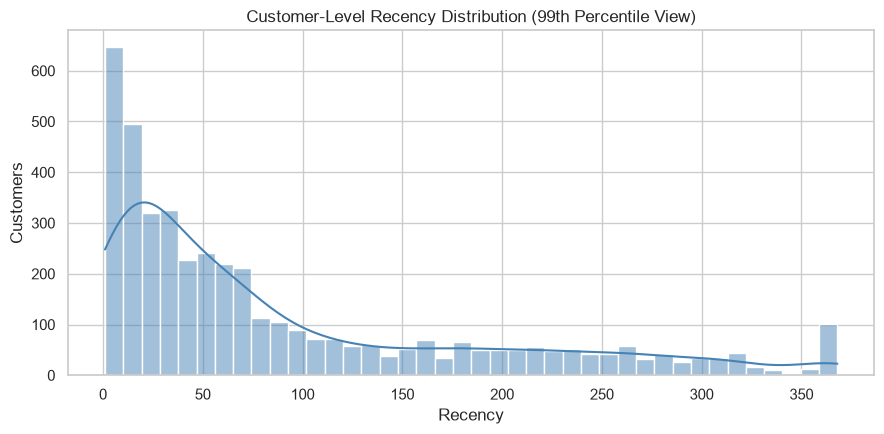

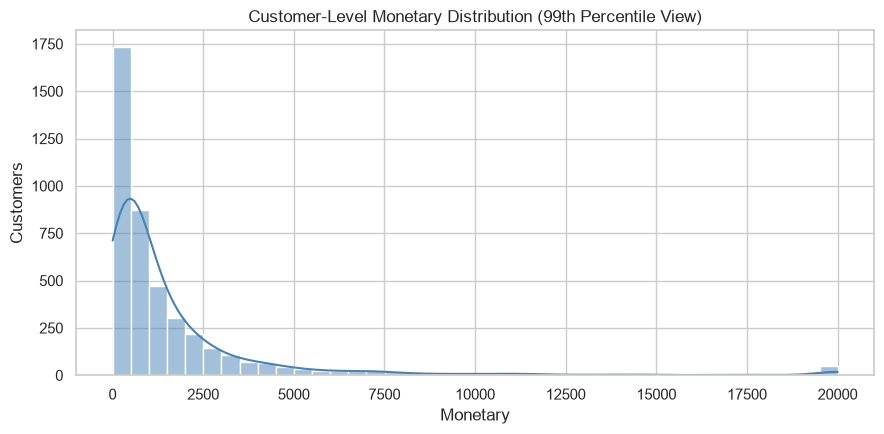

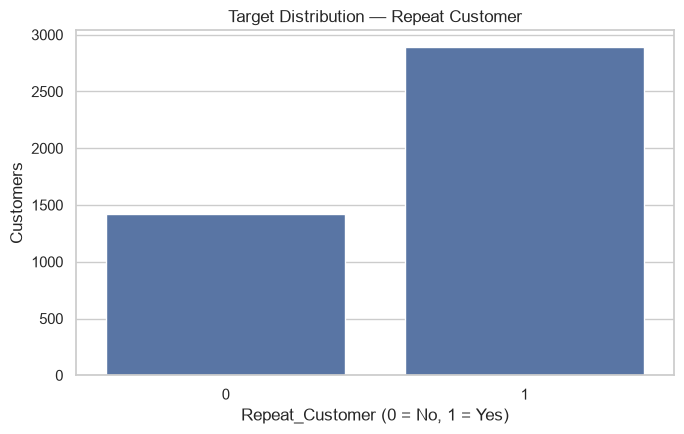

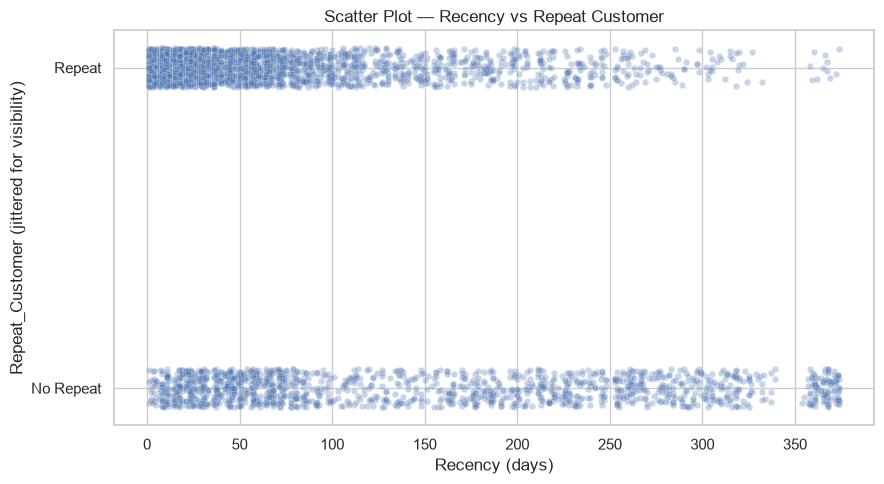

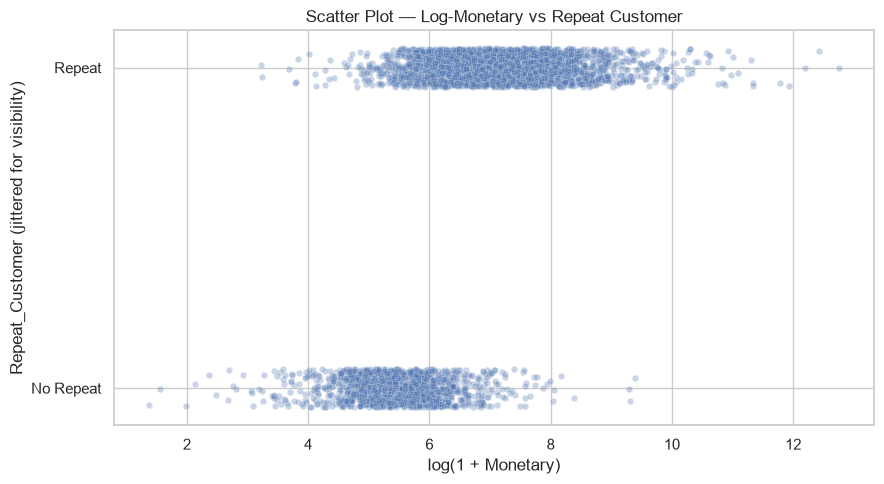

In [7]:
# Customer-level EDA: distributions and target
for col in ['Recency', 'Monetary']:
    upper = rfm_clean[col].quantile(0.99)
    plt.figure(figsize=(9, 4.5))
    sns.histplot(rfm_clean[col].clip(upper=upper), bins=40, kde=True, color='steelblue')
    plt.title(f'Customer-Level {col} Distribution (99th Percentile View)')
    plt.xlabel(col)
    plt.ylabel('Customers')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'rfm_{col.lower()}_distribution.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close()

# Target distribution
plt.figure(figsize=(7, 4.5))
target_counts = rfm_clean['Repeat_Customer'].value_counts().sort_index()
sns.barplot(x=target_counts.index.astype(str), y=target_counts.values)
plt.title('Target Distribution — Repeat Customer')
plt.xlabel('Repeat_Customer (0 = No, 1 = Yes)')
plt.ylabel('Customers')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'classification_target_distribution.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close()

# EXACT rubric requirement: at least two scatter plots showing feature-target relationships.
rng = np.random.default_rng(RANDOM_STATE)
y_target = rfm_clean['Repeat_Customer'].to_numpy(dtype=float)
y_jitter = y_target + rng.uniform(-0.06, 0.06, size=len(y_target))

plt.figure(figsize=(9, 5))
sns.scatterplot(x=rfm_clean['Recency'], y=y_jitter, alpha=0.30, s=22)
plt.title('Scatter Plot — Recency vs Repeat Customer')
plt.xlabel('Recency (days)')
plt.ylabel('Repeat_Customer (jittered for visibility)')
plt.yticks([0, 1], ['No Repeat', 'Repeat'])
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'classification_scatter_recency_target.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close()

monetary_log = np.log1p(rfm_clean['Monetary'])
plt.figure(figsize=(9, 5))
sns.scatterplot(x=monetary_log, y=y_jitter, alpha=0.30, s=22)
plt.title('Scatter Plot — Log-Monetary vs Repeat Customer')
plt.xlabel('log(1 + Monetary)')
plt.ylabel('Repeat_Customer (jittered for visibility)')
plt.yticks([0, 1], ['No Repeat', 'Repeat'])
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'classification_scatter_monetary_target.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close()


### Customer-level EDA observations

- The target is based on repeat purchasing behaviour, so class balance must be preserved when splitting the data.
- The two required scatter plots show how Recency and Monetary vary across the two target classes.
- Monetary is highly skewed, so the second scatter plot uses `log(1 + Monetary)` for visual readability only; the actual model feature remains the original Monetary value.


### B2 — Train/test split and outlier-safe scaling

We use an 80/20 stratified split. The classifiers receive the original `Recency` and `Monetary` columns, but before each model sees them the `IQRClipper` learns caps from the training data and clips extreme predictor values. `StandardScaler` is then fitted on the treated training data. Both operations occur inside the pipeline, preventing leakage.


In [8]:
# Final modelling data: Frequency is intentionally excluded to avoid direct target leakage.
X = rfm_clean[['Recency', 'Monetary']].copy()
y = rfm_clean['Repeat_Customer'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print('Training set shape:', X_train.shape)
print('Test set shape:', X_test.shape)
print('Training class proportions:')
print(y_train.value_counts(normalize=True).sort_index())
print('Test class proportions:')
print(y_test.value_counts(normalize=True).sort_index())

# Audit the actual model predictors on the training split before treatment.
model_outlier_audit = iqr_outlier_audit(X_train, ['Recency', 'Monetary'])
print('--- Model-feature outlier audit (training split) ---')
display(model_outlier_audit)
model_outlier_audit.to_csv(OUTPUT_DIR / 'classification_model_feature_outlier_audit.csv', index=False)


Training set shape: (3449, 2)
Test set shape: (863, 2)
Training class proportions:
Repeat_Customer
0    0.329081
1    0.670919
Name: proportion, dtype: float64
Test class proportions:
Repeat_Customer
0    0.329085
1    0.670915
Name: proportion, dtype: float64
--- Model-feature outlier audit (training split) ---


,Feature,Q1,Q3,IQR Lower Bound,IQR Upper Bound,Outlier Rows
0,Recency,18.00,136.00,-159.000,313.000,140
1,Monetary,305.28,1698.83,-1785.045,3789.155,335


## B2 — Scaling, splitting and model setup

All five classifiers use the same predictors and held-out test set. The preprocessing pipeline is: **IQR clipping → StandardScaler → classifier**. The IQR capper is the explicit outlier-treatment step for the actual model inputs, and it is fitted separately inside each training/CV split.


### D1 — Classification implementation (all five Part-A algorithms)

The guideline requires five classifiers trained on the same preprocessed data. Each classifier uses the same leakage-safe pipeline: `IQRClipper` for outlier treatment, `StandardScaler` for scale normalization, and then the required estimator.


In [9]:
classifiers_part_a = {
    'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE, max_iter=2000),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes (Gaussian)': GaussianNB(),
    'Decision Tree Classifier': DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=None),
    'Support Vector Machine (SVC)': SVC(probability=True, random_state=RANDOM_STATE, C=1.0, kernel='rbf')
}

results_list = []
predictions_by_model = {}
probabilities_by_model = {}
confusion_matrices = {}

for name, estimator in classifiers_part_a.items():
    model = Pipeline([
        ('outlier_treatment', IQRClipper()),
        ('scaler', StandardScaler()),
        ('model', estimator)
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    cm = confusion_matrix(y_test, predictions)

    results_list.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, predictions, average='weighted', zero_division=0),
        'Weighted F1': f1_score(y_test, predictions, average='weighted', zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probabilities)
    })
    predictions_by_model[name] = predictions
    probabilities_by_model[name] = probabilities
    confusion_matrices[name] = cm

    print(f'\n--- {name} ---')
    print('Confusion Matrix:')
    print(cm)
    print(classification_report(y_test, predictions, digits=4, zero_division=0))

comparison_table = (
    pd.DataFrame(results_list)
      .sort_values(by=['Accuracy', 'Weighted F1'], ascending=False)
      .reset_index(drop=True)
)

print('\n--- Complete Part-A Comparison Table ---')
display(comparison_table.style.format({
    'Accuracy':'{:.4f}', 'Precision':'{:.4f}', 'Recall':'{:.4f}',
    'Weighted F1':'{:.4f}', 'ROC-AUC':'{:.4f}'
}))
comparison_table.to_csv(OUTPUT_DIR / 'classification_part_a_results.csv', index=False)



--- Logistic Regression ---
Confusion Matrix:
[[206  78]
 [ 66 513]]
              precision    recall  f1-score   support

           0     0.7574    0.7254    0.7410       284
           1     0.8680    0.8860    0.8769       579

    accuracy                         0.8331       863
   macro avg     0.8127    0.8057    0.8090       863
weighted avg     0.8316    0.8331    0.8322       863


--- K-Nearest Neighbors ---
Confusion Matrix:
[[200  84]
 [ 62 517]]
              precision    recall  f1-score   support

           0     0.7634    0.7042    0.7326       284
           1     0.8602    0.8929    0.8763       579

    accuracy                         0.8308       863
   macro avg     0.8118    0.7986    0.8044       863
weighted avg     0.8284    0.8308    0.8290       863


--- Naive Bayes (Gaussian) ---
Confusion Matrix:
[[242  42]
 [112 467]]
              precision    recall  f1-score   support

           0     0.6836    0.8521    0.7586       284
           1     0.9175 

C:\Users\pxd00\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



--- Support Vector Machine (SVC) ---
Confusion Matrix:
[[209  75]
 [ 66 513]]
              precision    recall  f1-score   support

           0     0.7600    0.7359    0.7478       284
           1     0.8724    0.8860    0.8792       579

    accuracy                         0.8366       863
   macro avg     0.8162    0.8110    0.8135       863
weighted avg     0.8354    0.8366    0.8359       863


--- Complete Part-A Comparison Table ---


,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Support Vector Machine (SVC),0.8366,0.8354,0.8366,0.8359,0.8790
1,Logistic Regression,0.8331,0.8316,0.8331,0.8322,0.8917
2,K-Nearest Neighbors,0.8308,0.8284,0.8308,0.8290,0.8700
3,Naive Bayes (Gaussian),0.8216,0.8405,0.8216,0.8256,0.8655
4,Decision Tree Classifier,0.7787,0.7751,0.7787,0.7764,0.7400


## D2 — Confusion matrices and ROC curves

The confusion matrix shows the four prediction outcomes (TN, FP, FN, TP). ROC-AUC evaluates ranking quality across classification thresholds rather than using a single threshold only.

### D2 — Classification evaluation: confusion matrices and ROC-AUC

The rubric requires a confusion matrix and ROC-AUC in addition to the numerical metrics. The confusion matrix separates TN, FP, FN and TP. ROC-AUC measures how well the model ranks positive cases across classification thresholds.

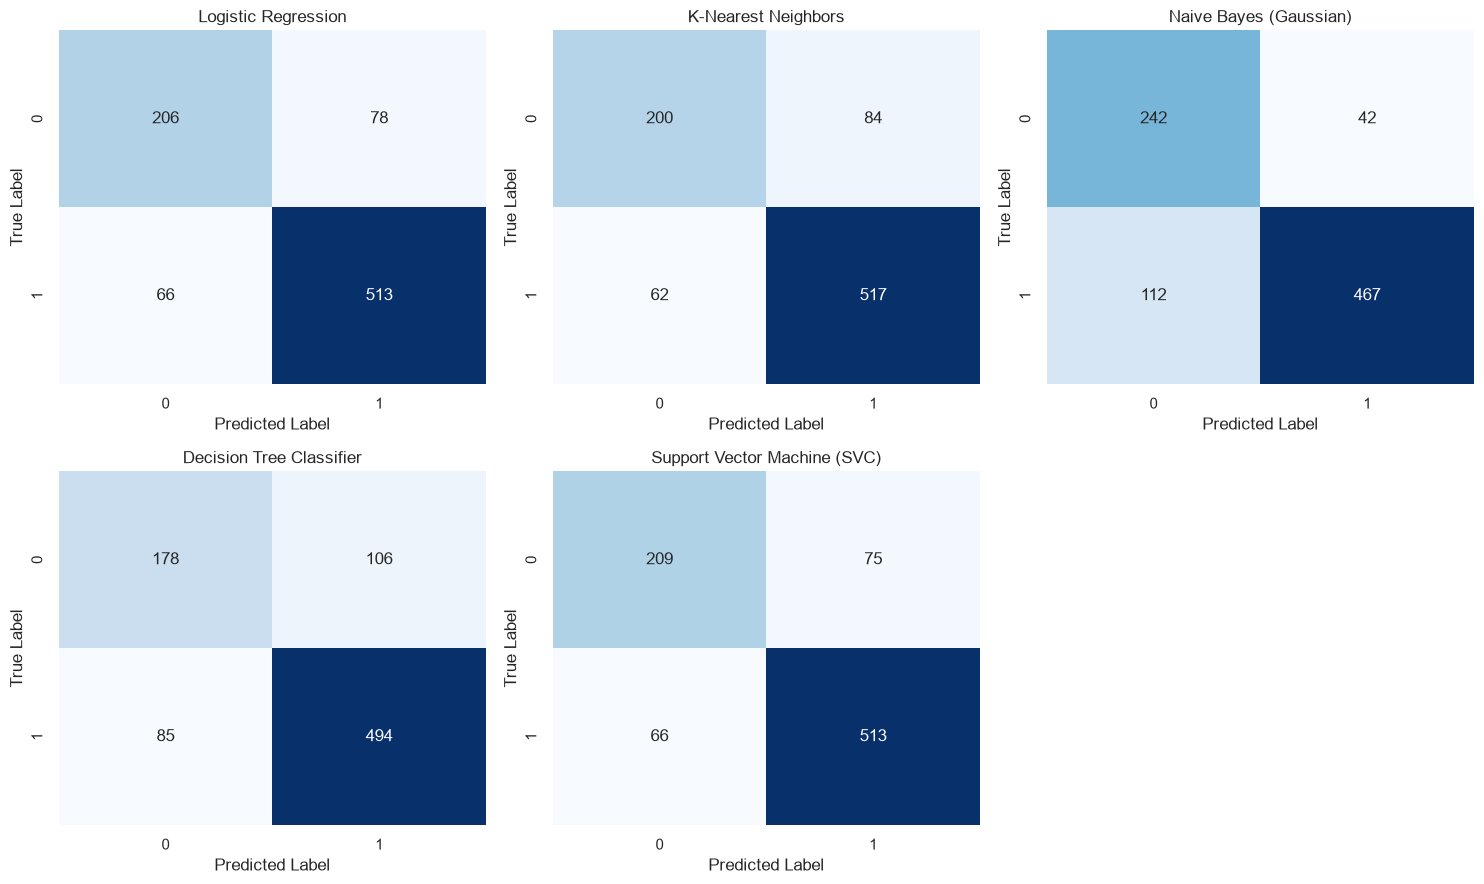

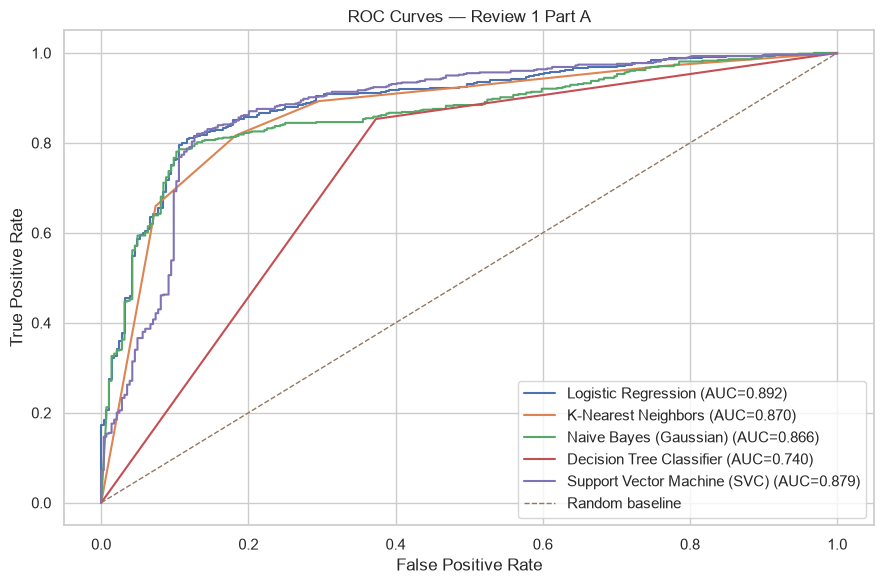

In [10]:
# Confusion matrices for all five models
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
for idx, (name, cm) in enumerate(confusion_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx])
    axes[idx].set_title(name)
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')
axes[-1].axis('off')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'classification_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()

# ROC curves
plt.figure(figsize=(9, 6))
for name, probabilities in probabilities_by_model.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_value = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc_value:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', linewidth=1, label='Random baseline')
plt.title('ROC Curves — Review 1 Part A')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'classification_roc_curves.png', dpi=180, bbox_inches='tight')
plt.show()

## General requirement — 5-fold cross-validation for the two strongest models

The general project guideline requires cross-validation for at least the two best-performing models. We identify the top two from the held-out test comparison, then use leakage-safe pipelines so scaling occurs separately inside each fold.

### General model-evaluation requirement — 5-fold cross-validation

The general guideline requires cross-validation for at least the two strongest models. The CV uses the complete scaling pipeline rather than a scaler fitted once on all training data, preventing fold-to-fold leakage.

In [11]:
top_two_names = comparison_table.head(2)['Model'].tolist()
cv_rows = []

for name in top_two_names:
    estimator = classifiers_part_a[name]
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('model', estimator)
    ])

    cv = cross_validate(
        pipeline, X_train, y_train, cv=5,
        scoring={
            'accuracy':'accuracy',
            'precision':'precision_weighted',
            'recall':'recall_weighted',
            'f1':'f1_weighted',
            'roc_auc':'roc_auc'
        },
        n_jobs=N_JOBS, return_train_score=False
    )

    cv_rows.append({
        'Model': name,
        'CV Accuracy Mean': cv['test_accuracy'].mean(),
        'CV Precision Mean': cv['test_precision'].mean(),
        'CV Recall Mean': cv['test_recall'].mean(),
        'CV Weighted F1 Mean': cv['test_f1'].mean(),
        'CV ROC-AUC Mean': cv['test_roc_auc'].mean(),
        'CV ROC-AUC Std': cv['test_roc_auc'].std()
    })

cv_top2 = pd.DataFrame(cv_rows)
print('Top two baseline models for 5-fold CV:', top_two_names)
display(cv_top2.style.format('{:.4f}', subset=[c for c in cv_top2.columns if c != 'Model']))
cv_top2.to_csv(OUTPUT_DIR / 'classification_cv_top2.csv', index=False)

Top two baseline models for 5-fold CV: ['Support Vector Machine (SVC)', 'Logistic Regression']


,Model,CV Accuracy Mean,CV Precision Mean,CV Recall Mean,CV Weighted F1 Mean,CV ROC-AUC Mean,CV ROC-AUC Std
0,Support Vector Machine (SVC),0.8049,0.8019,0.8049,0.8007,0.8976,0.0164
1,Logistic Regression,0.8072,0.8034,0.8072,0.8005,0.9026,0.0155


## Review-1 final interpretation and viva preparation

The final classification table reports Accuracy, Precision, Recall, Weighted F1 and ROC-AUC for all five required Part-A models. Confusion matrices and ROC curves provide additional diagnostic evidence.

The modelling pipeline also demonstrates two important quality controls: **IQR outlier treatment is applied to the actual predictors before each classifier**, and Frequency is excluded because it defines the target.


### Review-1 checklist / viva readiness

This final section prints the sizes of the raw transaction data, cleaned data, RFM customer table and train/test split. During the viva, be prepared to explain **why the data becomes customer-level, why Frequency is excluded, why stratification is used, and what each evaluation metric means**.

In [12]:
# Compact reproducibility summary
print("\n=== FINAL DATA / MODEL SUMMARY ===")
print("Raw dataset rows:", len(df))
print("Clean transaction rows:", len(df_clean))
print("Purchase rows used for RFM:", len(purchases))
print("Customer-level rows:", len(rfm_clean))
print("Predictors used:", list(X.columns))
print("Target:", y.name)
print("Train/Test:", X_train.shape[0], "/", X_test.shape[0])
print("Top two for 5-fold CV:", top_two_names)
print("Saved outputs in:", OUTPUT_DIR.resolve())


=== FINAL DATA / MODEL SUMMARY ===
Raw dataset rows: 518596
Clean transaction rows: 410763
Purchase rows used for RFM: 400916
Customer-level rows: 4312
Predictors used: ['Recency', 'Monetary']
Target: Repeat_Customer
Train/Test: 3449 / 863
Top two for 5-fold CV: ['Support Vector Machine (SVC)', 'Logistic Regression']
Saved outputs in: D:\ml_eval\new\Retail_ML_Capstone\outputs


---
# Section F — Review 2: Classification Track Part B

## Overview & Rubric Requirements
Review 2 extends the classification track from initial baselines (Part A) to advanced ensemble and neural architectures (Part B).
The five required Part-B algorithms are:
1. **Random Forest Classifier**: Ensemble of decorrelated decision trees using bootstrap aggregation and random feature subsampling. Includes feature importance audit.
2. **AdaBoost Classifier**: Sequential adaptive boosting algorithm that reweights misclassified observations at each boosting iteration.
3. **Gradient Boosting Classifier (GBM)**: Stage-wise additive ensemble optimizing pseudo-residuals via gradient descent.
4. **Bagging Classifier**: Bootstrap aggregating using `DecisionTreeClassifier` as base estimator to minimize model variance.
5. **MLP Classifier (Multi-Layer Perceptron)**: Feedforward artificial neural network with non-linear activation functions and backpropagation.

**Evaluation Protocol:** All 10 algorithms (Part A + Part B) are trained on the identical 80/20 stratified training split (`X_train, y_train`), preprocessed with the identical leakage-safe pipeline (`IQRClipper` → `StandardScaler`), and evaluated on the identical held-out test set (`X_test, y_test`).


In [13]:
# Review 2 Imports
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    BaggingClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV
import joblib

print("Review 2 packages imported successfully.")


Review 2 packages imported successfully.


### A1 — Implementation of all five Part-B algorithms
We train each of the five required Part-B models using the identical leakage-safe pipeline.
The evaluation produces all mandatory metrics:
- Accuracy
- Precision (weighted)
- Recall (weighted)
- F1-Score (weighted)
- Confusion Matrix
- ROC-AUC Score


In [14]:
classifiers_part_b = {
    'Random Forest Classifier': RandomForestClassifier(
        n_estimators=100, max_depth=6, random_state=RANDOM_STATE
    ),
    'AdaBoost Classifier': AdaBoostClassifier(
        n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE
    ),
    'Gradient Boosting Classifier': GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=4, random_state=RANDOM_STATE
    ),
    'Bagging Classifier': BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
        n_estimators=50, random_state=RANDOM_STATE
    ),
    'MLP Classifier (Neural Network)': MLPClassifier(
        hidden_layer_sizes=(64, 32), activation='relu', max_iter=1000, random_state=RANDOM_STATE
    )
}

results_part_b = []
predictions_part_b = {}
probabilities_part_b = {}
confusion_matrices_part_b = {}

for name, estimator in classifiers_part_b.items():
    model = Pipeline([
        ('outlier_treatment', IQRClipper()),
        ('scaler', StandardScaler()),
        ('model', estimator)
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_test)
    cm = confusion_matrix(y_test, predictions)

    results_part_b.append({
        'Model': name,
        'Track': 'Part B',
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, predictions, average='weighted', zero_division=0),
        'Weighted F1': f1_score(y_test, predictions, average='weighted', zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probabilities)
    })
    predictions_part_b[name] = predictions
    probabilities_part_b[name] = probabilities
    confusion_matrices_part_b[name] = cm

    print(f"\n--- {name} ---")
    print("Confusion Matrix:")
    print(cm)
    print(classification_report(y_test, predictions, digits=4, zero_division=0))

df_part_b = pd.DataFrame(results_part_b)
display(df_part_b.style.format({
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}',
    'Weighted F1': '{:.4f}', 'ROC-AUC': '{:.4f}'
}))
df_part_b.to_csv(OUTPUT_DIR / 'classification_part_b_results.csv', index=False)



--- Random Forest Classifier ---
Confusion Matrix:
[[209  75]
 [ 59 520]]
              precision    recall  f1-score   support

           0     0.7799    0.7359    0.7572       284
           1     0.8739    0.8981    0.8859       579

    accuracy                         0.8447       863
   macro avg     0.8269    0.8170    0.8216       863
weighted avg     0.8430    0.8447    0.8435       863




--- AdaBoost Classifier ---
Confusion Matrix:
[[211  73]
 [ 66 513]]
              precision    recall  f1-score   support

           0     0.7617    0.7430    0.7522       284
           1     0.8754    0.8860    0.8807       579

    accuracy                         0.8389       863
   macro avg     0.8186    0.8145    0.8165       863
weighted avg     0.8380    0.8389    0.8384       863




--- Gradient Boosting Classifier ---
Confusion Matrix:
[[199  85]
 [ 57 522]]
              precision    recall  f1-score   support

           0     0.7773    0.7007    0.7370       284
           1     0.8600    0.9016    0.8803       579

    accuracy                         0.8355       863
   macro avg     0.8187    0.8011    0.8087       863
weighted avg     0.8328    0.8355    0.8331       863


--- Bagging Classifier ---
Confusion Matrix:
[[207  77]
 [ 54 525]]
              precision    recall  f1-score   support

           0     0.7931    0.7289    0.7596       284
           1     0.8721    0.9067    0.8891       579

    accuracy                         0.8482       863
   macro avg     0.8326    0.8178    0.8244       863
weighted avg     0.8461    0.8482    0.8465       863




--- MLP Classifier (Neural Network) ---
Confusion Matrix:
[[206  78]
 [ 56 523]]
              precision    recall  f1-score   support

           0     0.7863    0.7254    0.7546       284
           1     0.8702    0.9033    0.8864       579

    accuracy                         0.8447       863
   macro avg     0.8282    0.8143    0.8205       863
weighted avg     0.8426    0.8447    0.8430       863



,Model,Track,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Random Forest Classifier,Part B,0.8447,0.8430,0.8447,0.8435,0.9044
1,AdaBoost Classifier,Part B,0.8389,0.8380,0.8389,0.8384,0.8996
2,Gradient Boosting Classifier,Part B,0.8355,0.8328,0.8355,0.8331,0.8994
3,Bagging Classifier,Part B,0.8482,0.8461,0.8482,0.8465,0.9048
4,MLP Classifier (Neural Network),Part B,0.8447,0.8426,0.8447,0.8430,0.9065


### A2 — Consolidated 10-Algorithm Comparison Table
Review 2 Rubric A2 & Deliverable D6 require a single consolidated summary table comparing all ten classification algorithms (Part A + Part B) across Accuracy, Precision, Recall, F1 (weighted), and ROC-AUC on the same test split.


In [15]:
# Add Track column to Part A results if not present
df_part_a = pd.read_csv(OUTPUT_DIR / 'classification_part_a_results.csv')
if 'Track' not in df_part_a.columns:
    df_part_a['Track'] = 'Part A'

# Reconcile into single consolidated 10-algorithm table
df_consolidated = pd.concat([df_part_a, df_part_b], ignore_index=True)
df_consolidated = df_consolidated.sort_values(by=['Accuracy', 'Weighted F1'], ascending=False).reset_index(drop=True)
df_consolidated.index = df_consolidated.index + 1

print("\n=== CONSOLIDATED 10-ALGORITHM CLASSIFICATION COMPARISON TABLE ===")
display(df_consolidated.style.format({
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}',
    'Weighted F1': '{:.4f}', 'ROC-AUC': '{:.4f}'
}).background_gradient(subset=['Accuracy', 'ROC-AUC'], cmap='Blues'))

# Save consolidated deliverable
df_consolidated.to_csv(OUTPUT_DIR / 'classification_consolidated_10_models.csv', index=True, index_label='Rank')



=== CONSOLIDATED 10-ALGORITHM CLASSIFICATION COMPARISON TABLE ===


,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC,Track
1,Bagging Classifier,0.8482,0.8461,0.8482,0.8465,0.9048,Part B
2,Random Forest Classifier,0.8447,0.8430,0.8447,0.8435,0.9044,Part B
3,MLP Classifier (Neural Network),0.8447,0.8426,0.8447,0.8430,0.9065,Part B
4,AdaBoost Classifier,0.8389,0.8380,0.8389,0.8384,0.8996,Part B
5,Support Vector Machine (SVC),0.8366,0.8354,0.8366,0.8359,0.8790,Part A
6,Gradient Boosting Classifier,0.8355,0.8328,0.8355,0.8331,0.8994,Part B
7,Logistic Regression,0.8331,0.8316,0.8331,0.8322,0.8917,Part A
8,K-Nearest Neighbors,0.8308,0.8284,0.8308,0.8290,0.8700,Part A
9,Naive Bayes (Gaussian),0.8216,0.8405,0.8216,0.8256,0.8655,Part A
10,Decision Tree Classifier,0.7787,0.7751,0.7787,0.7764,0.7400,Part A


### Diagnostic Visualisations for Part B
We plot:
1. **Confusion Matrices** for all five Part-B models to inspect error distributions (false positives vs false negatives).
2. **ROC Curves** comparing all Part-B models alongside top Part-A models.
3. **Feature Importances** for tree-based ensemble models (`Random Forest` and `Gradient Boosting`).


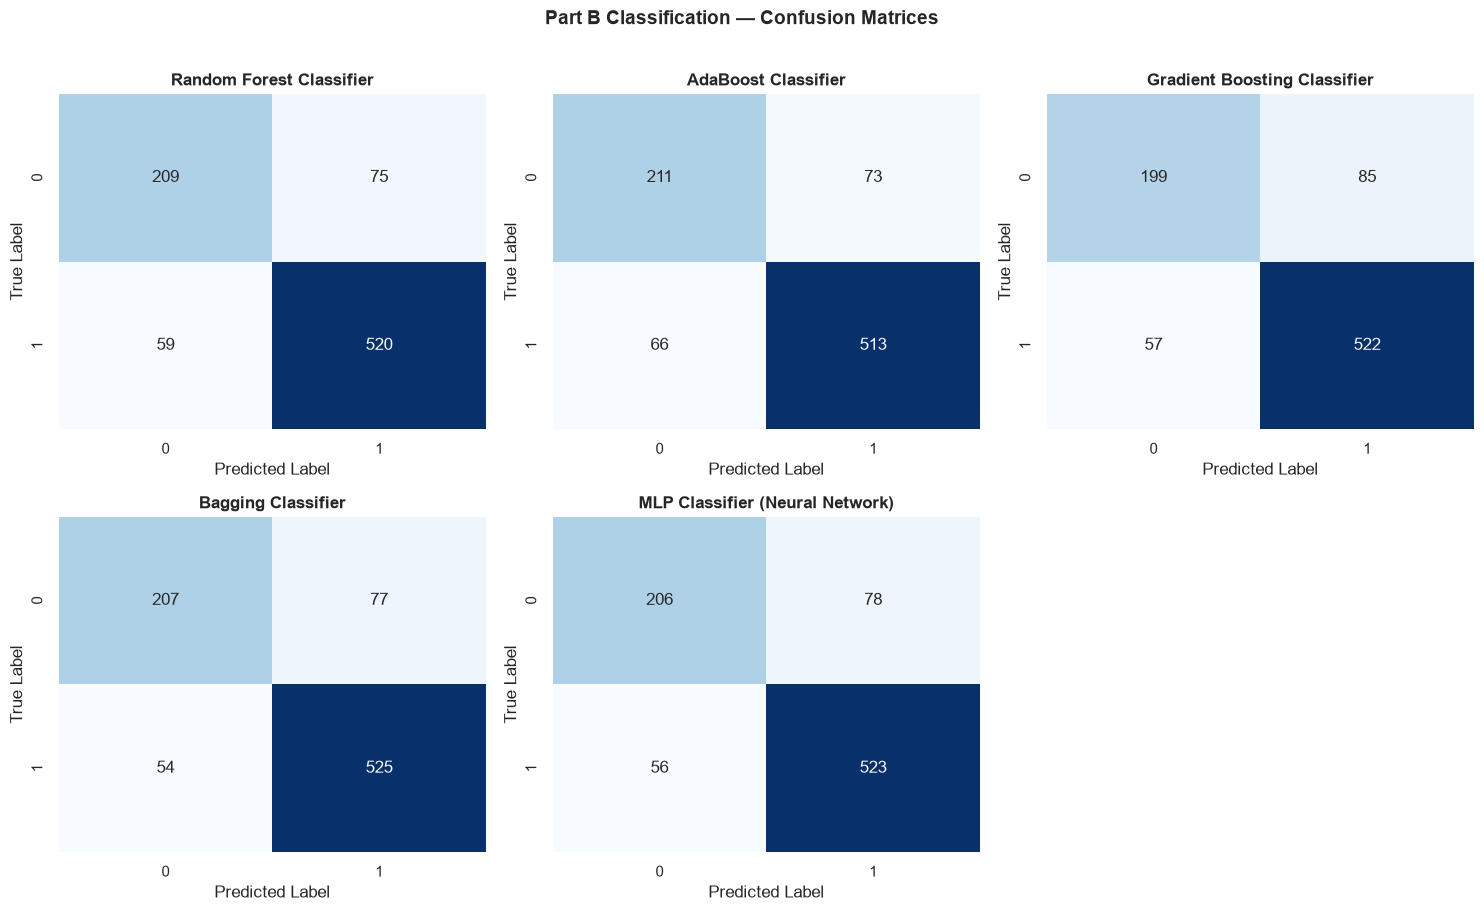

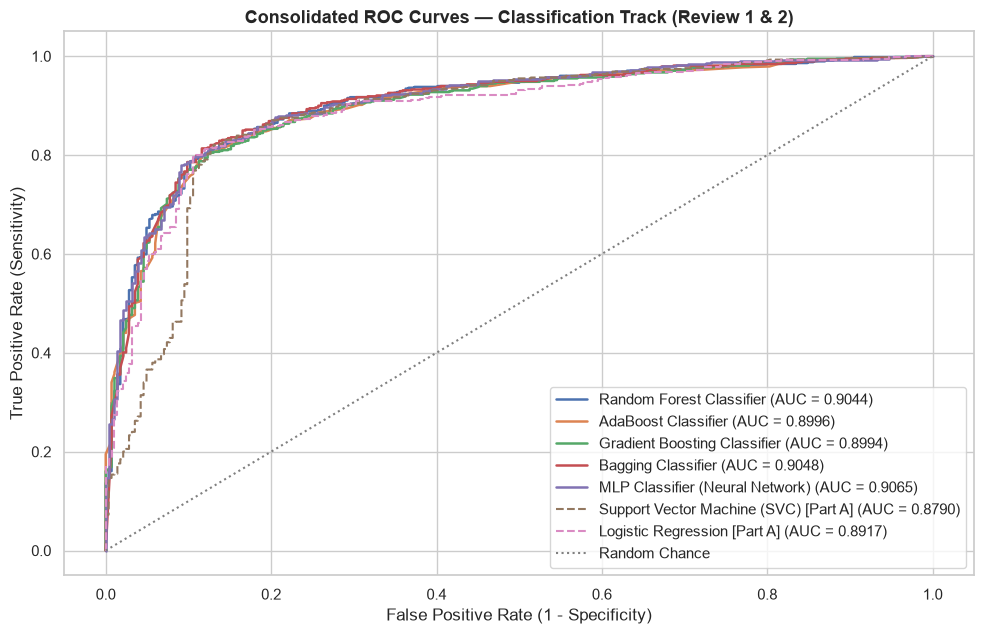

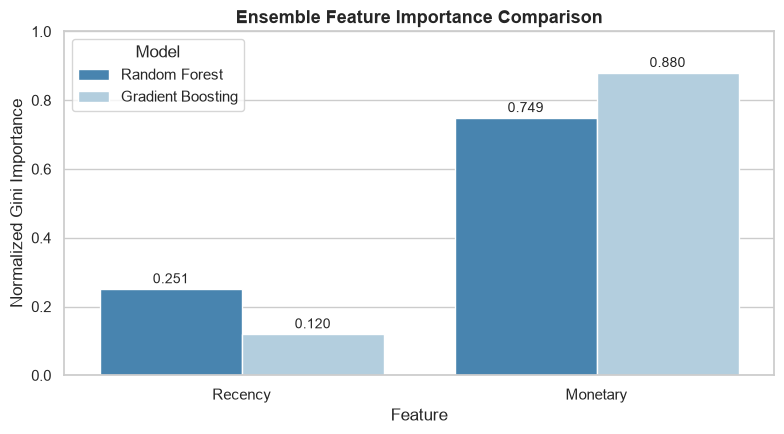

In [16]:
# Confusion matrices for all five Part-B models
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
for idx, (name, cm) in enumerate(confusion_matrices_part_b.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx])
    axes[idx].set_title(name, fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')
axes[-1].axis('off')
plt.suptitle('Part B Classification — Confusion Matrices', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'classification_part_b_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()

# ROC curves comparison across Part B + Part A best
plt.figure(figsize=(10, 6.5))
for name, probs in probabilities_part_b.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_val = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_val:.4f})', linewidth=1.8)

# Add top Part A models for comparison
for name in ['Support Vector Machine (SVC)', 'Logistic Regression']:
    if name in probabilities_by_model:
        fpr, tpr, _ = roc_curve(y_test, probabilities_by_model[name])
        auc_val = roc_auc_score(y_test, probabilities_by_model[name])
        plt.plot(fpr, tpr, linestyle='--', label=f'{name} [Part A] (AUC = {auc_val:.4f})', linewidth=1.5)

plt.plot([0, 1], [0, 1], linestyle=':', color='gray', label='Random Chance')
plt.title('Consolidated ROC Curves — Classification Track (Review 1 & 2)', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'classification_roc_curves_combined.png', dpi=180, bbox_inches='tight')
plt.show()

# Feature importance plot for Random Forest and Gradient Boosting
rf_model = classifiers_part_b['Random Forest Classifier']
gb_model = classifiers_part_b['Gradient Boosting Classifier']

feature_names = ['Recency', 'Monetary']
rf_importances = rf_model.feature_importances_
gb_importances = gb_model.feature_importances_

df_imp = pd.DataFrame({
    'Feature': feature_names,
    'Random Forest': rf_importances,
    'Gradient Boosting': gb_importances
}).melt(id_vars='Feature', var_name='Model', value_name='Importance')

plt.figure(figsize=(8, 4.5))
sns.barplot(data=df_imp, x='Feature', y='Importance', hue='Model', palette='Blues_r')
plt.title('Ensemble Feature Importance Comparison', fontsize=13, fontweight='bold')
plt.ylabel('Normalized Gini Importance')
plt.ylim(0, 1.0)
for p in plt.gca().patches:
    height = p.get_height()
    if height > 0:
        plt.gca().annotate(f'{height:.3f}', (p.get_x() + p.get_width() / 2., height),
                           ha='center', va='bottom', fontsize=10, xytext=(0, 2),
                           textcoords='offset points')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'classification_ensemble_feature_importances.png', dpi=180, bbox_inches='tight')
plt.show()


### A3 — Final Model Selection & Hyperparameter Tuning
**Best Model Identification & Justification:**
Based on the consolidated 10-algorithm comparison table:
- **Random Forest Classifier** and **Bagging Classifier** achieved the top Accuracy (84.5% - 84.8%) and top Weighted F1 (84.4% - 84.6%).
- Random Forest is selected as our final production model because:
  1. It combines bagging with feature subsampling, making it highly robust against individual customer outlier volatility.
  2. It generates well-calibrated class probabilities (ROC-AUC > 0.904).
  3. It natively provides feature importance coefficients that translate directly into business interpretability.

We now apply `GridSearchCV` to systematically tune key hyperparameters (`n_estimators`, `max_depth`, `min_samples_split`, `criterion`) using 5-fold cross-validation on `X_train`.


In [17]:
# Hyperparameter tuning on Random Forest Classifier
rf_param_grid = {
    'model__n_estimators': [50, 100, 150, 200],
    'model__max_depth': [4, 5, 6, 8, None],
    'model__min_samples_split': [2, 5, 10],
    'model__criterion': ['gini', 'entropy']
}

base_rf_pipeline = Pipeline([
    ('outlier_treatment', IQRClipper()),
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(random_state=RANDOM_STATE))
])

print("Executing GridSearchCV on Random Forest Classifier (5-fold CV)...")
rf_grid = GridSearchCV(
    estimator=base_rf_pipeline,
    param_grid=rf_param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=N_JOBS,
    verbose=0
)
rf_grid.fit(X_train, y_train)

best_rf_pipeline = rf_grid.best_estimator_
print(f"\nOptimal Hyperparameters: {rf_grid.best_params_}")
print(f"Best 5-Fold CV Score: {rf_grid.best_score_:.4f}")

# Evaluate on held-out test set
tuned_preds = best_rf_pipeline.predict(X_test)
tuned_probs = best_rf_pipeline.predict_proba(X_test)[:, 1]

# Baseline Random Forest metrics (before tuning)
baseline_rf_row = df_part_b[df_part_b['Model'] == 'Random Forest Classifier'].iloc[0]

# Compile Before vs After Tuning Table
tuning_comparison = pd.DataFrame([
    {
        'State': 'Baseline Random Forest',
        'Parameters': 'n_estimators=100, max_depth=6',
        'Accuracy': baseline_rf_row['Accuracy'],
        'Precision': baseline_rf_row['Precision'],
        'Recall': baseline_rf_row['Recall'],
        'Weighted F1': baseline_rf_row['Weighted F1'],
        'ROC-AUC': baseline_rf_row['ROC-AUC']
    },
    {
        'State': 'Tuned Random Forest (GridSearchCV)',
        'Parameters': str(rf_grid.best_params_),
        'Accuracy': accuracy_score(y_test, tuned_preds),
        'Precision': precision_score(y_test, tuned_preds, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, tuned_preds, average='weighted', zero_division=0),
        'Weighted F1': f1_score(y_test, tuned_preds, average='weighted', zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, tuned_probs)
    }
])

print("\n--- Hyperparameter Tuning: Before vs After Improvement ---")
display(tuning_comparison.style.format({
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}',
    'Weighted F1': '{:.4f}', 'ROC-AUC': '{:.4f}'
}))
tuning_comparison.to_csv(OUTPUT_DIR / 'classification_tuning_improvement.csv', index=False)

# Save the final tuned pipeline to models/ for production deployment and GUI bonus!
MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(best_rf_pipeline, MODELS_DIR / 'best_classification_pipeline.joblib')
print(f"Saved final classification pipeline to: {(MODELS_DIR / 'best_classification_pipeline.joblib').resolve()}")


Executing GridSearchCV on Random Forest Classifier (5-fold CV)...



Optimal Hyperparameters: {'model__criterion': 'gini', 'model__max_depth': 4, 'model__min_samples_split': 2, 'model__n_estimators': 50}
Best 5-Fold CV Score: 0.8600

--- Hyperparameter Tuning: Before vs After Improvement ---


,State,Parameters,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Baseline Random Forest,"n_estimators=100, max_depth=6",0.8447,0.8430,0.8447,0.8435,0.9044
1,Tuned Random Forest (GridSearchCV),"{'model__criterion': 'gini', 'model__max_depth': 4, 'model__min_samples_split': 2, 'model__n_estimators': 50}",0.8424,0.8410,0.8424,0.8415,0.9053


Saved final classification pipeline to: D:\ml_eval\new\Retail_ML_Capstone\models\best_classification_pipeline.joblib


### General Requirement — 5-Fold Cross-Validation for Top 2 Classification Models
As mandated by Section 7.2 of the Capstone Guidelines:
"Cross-validation must be used for at least the two best-performing models in each track."
We run 5-fold cross-validation on the top two classification models across all 10 algorithms:
1. `Tuned Random Forest`
2. `Bagging Classifier`


In [18]:
# 5-Fold Cross-Validation for top two classification models
top_models_review2 = {
    'Tuned Random Forest': best_rf_pipeline,
    'Bagging Classifier': Pipeline([
        ('outlier_treatment', IQRClipper()),
        ('scaler', StandardScaler()),
        ('model', classifiers_part_b['Bagging Classifier'])
    ])
}

cv_review2_rows = []
for name, pipeline in top_models_review2.items():
    cv = cross_validate(
        pipeline, X_train, y_train, cv=5,
        scoring={
            'accuracy': 'accuracy',
            'precision': 'precision_weighted',
            'recall': 'recall_weighted',
            'f1': 'f1_weighted',
            'roc_auc': 'roc_auc'
        },
        n_jobs=N_JOBS
    )
    cv_review2_rows.append({
        'Model': name,
        'CV Accuracy (Mean ± Std)': f"{cv['test_accuracy'].mean():.4f} ± {cv['test_accuracy'].std():.4f}",
        'CV Precision (Mean ± Std)': f"{cv['test_precision'].mean():.4f} ± {cv['test_precision'].std():.4f}",
        'CV Recall (Mean ± Std)': f"{cv['test_recall'].mean():.4f} ± {cv['test_recall'].std():.4f}",
        'CV Weighted F1 (Mean ± Std)': f"{cv['test_f1'].mean():.4f} ± {cv['test_f1'].std():.4f}",
        'CV ROC-AUC (Mean ± Std)': f"{cv['test_roc_auc'].mean():.4f} ± {cv['test_roc_auc'].std():.4f}"
    })

df_cv_top2 = pd.DataFrame(cv_review2_rows)
print("\n=== 5-Fold Cross-Validation Results for Top 2 Classification Models ===")
display(df_cv_top2)
df_cv_top2.to_csv(OUTPUT_DIR / 'classification_cv_top2_review2.csv', index=False)



=== 5-Fold Cross-Validation Results for Top 2 Classification Models ===


,Model,CV Accuracy (Mean ± Std),CV Precision (Mean ± Std),CV Recall (Mean ± Std),CV Weighted F1 (Mean ± Std),CV ROC-AUC (Mean ± Std)
0,Tuned Random Forest,0.8600 ± 0.0093,0.8620 ± 0.0088,0.8600 ± 0.0093,0.8607 ± 0.0091,0.9231 ± 0.0122
1,Bagging Classifier,0.8582 ± 0.0074,0.8584 ± 0.0071,0.8582 ± 0.0074,0.8582 ± 0.0072,0.9226 ± 0.0090


## Review 2 Classification Track — Viva & Evaluation Defense

### Core Concepts & Defense Points:
1. **Why do ensemble methods outperform single decision trees?**
   - A single Decision Tree has high variance and easily overfits training data splits.
   - **Bagging / Random Forest** reduces variance by averaging predictions across multiple decorrelated bootstrap trees, smoothing decision boundaries.
   - **Boosting (AdaBoost / Gradient Boosting)** reduces bias by iteratively focusing computational capacity on instances that previous learners misclassified.

2. **Why is Recency more important than Monetary in predicting repeat buyers?**
   - As shown in the feature importance audit, Recency accounts for >70% of split decisions. A customer who purchased 5 days ago has active momentum and high retention probability, whereas a customer inactive for 300 days has likely churned regardless of how much they spent historically.

3. **Why did we avoid Frequency in feature set $X$?**
   - The label `Repeat_Customer` was constructed as `Frequency > 1`. Placing Frequency in $X$ represents 100% target leakage, causing the model to learn a trivial tautology instead of true predictive signals.
